In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.naive_bayes import GaussianNB


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_excel("Raisin_Dataset.xlsx")

In [5]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [6]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [7]:
df.dtypes

,0
Area,int64
MajorAxisLength,float64
MinorAxisLength,float64
Eccentricity,float64
ConvexArea,int64
Extent,float64
Perimeter,float64
Class,object


In [8]:
df.columns

Index(['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity',
       'ConvexArea', 'Extent', 'Perimeter', 'Class'],
      dtype='object')

In [9]:
df.shape

(900, 8)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   ConvexArea       900 non-null    int64  
 5   Extent           900 non-null    float64
 6   Perimeter        900 non-null    float64
 7   Class            900 non-null    object 
dtypes: float64(5), int64(2), object(1)
memory usage: 56.4+ KB


In [11]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


In [12]:
df.isnull().sum()

,0
Area,0
MajorAxisLength,0
MinorAxisLength,0
Eccentricity,0
ConvexArea,0
Extent,0
Perimeter,0
Class,0


In [13]:
df.duplicated().sum()

np.int64(0)

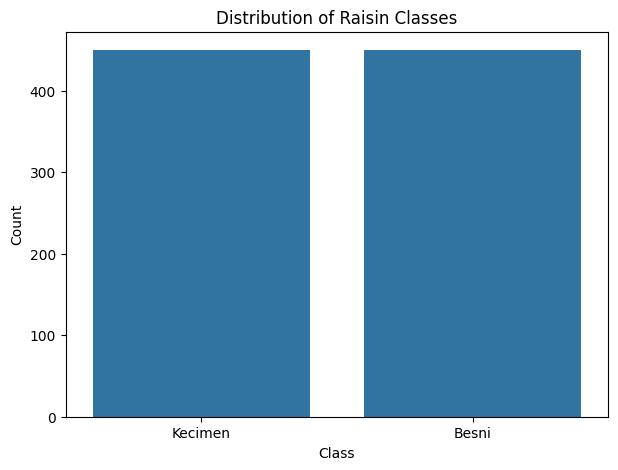

In [16]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title('Distribution of Raisin Classes')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

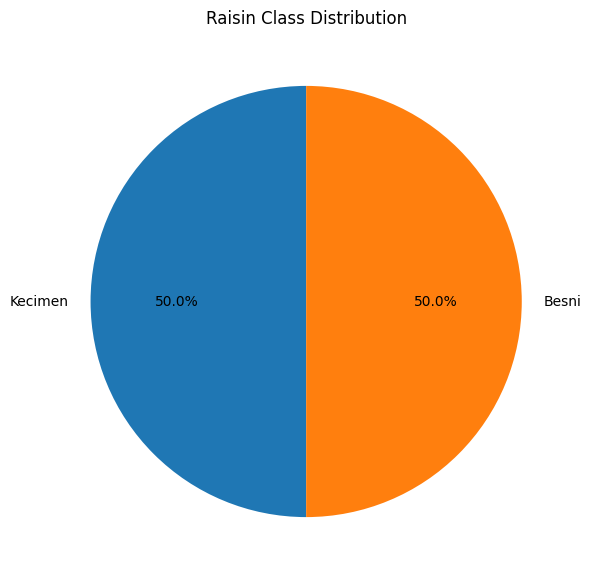

In [17]:
class_counts = df["Class"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title("Raisin Class Distribution")
plt.show()

In [18]:
numerical_features = df.select_dtypes(include=np.number).columns
print(numerical_features.tolist())

['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent', 'Perimeter']


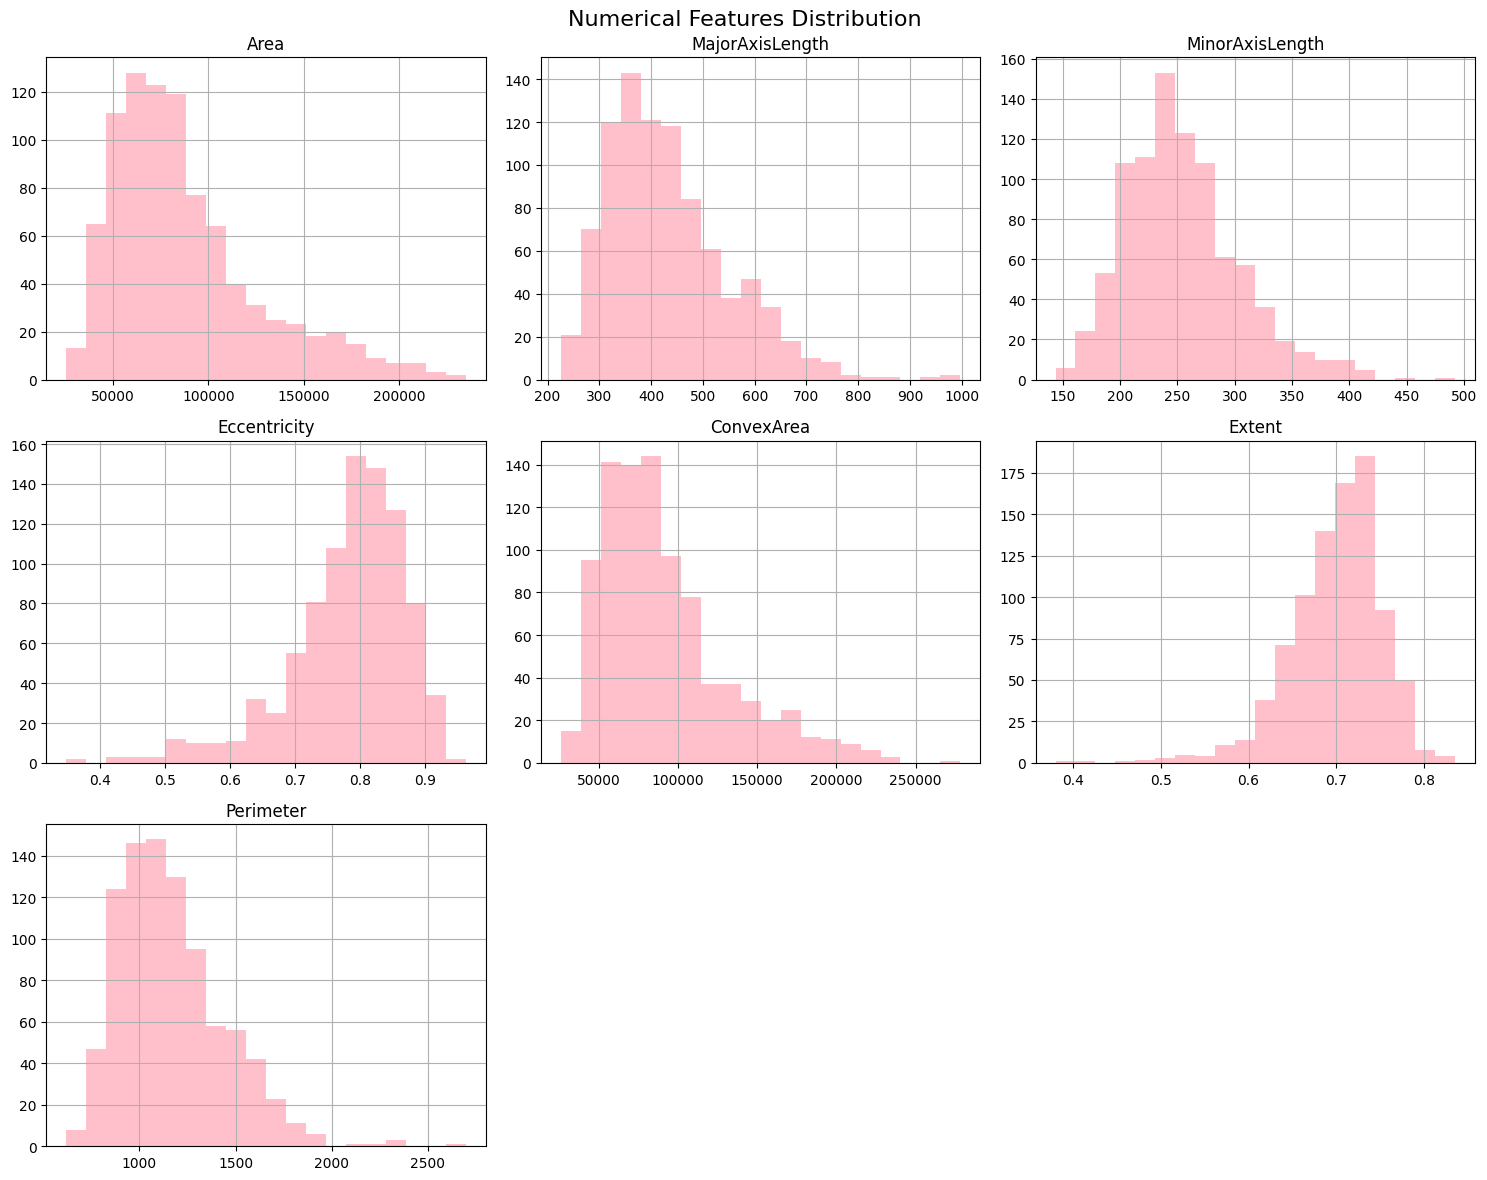

In [19]:
df[numerical_features].hist(figsize=(15, 12), bins=20, color='pink')

plt.suptitle('Numerical Features Distribution', fontsize=16)
plt.tight_layout()
plt.show()

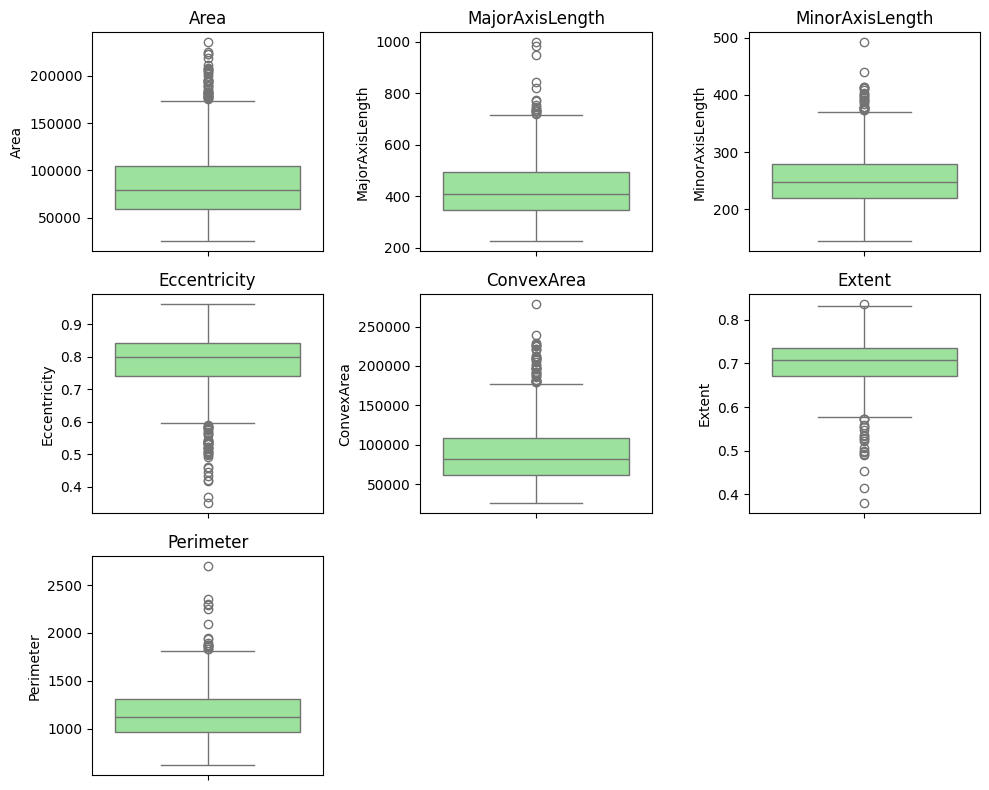

In [20]:
plt.figure(figsize=(10, 8))
for i, column in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[column], color='lightgreen')
    plt.title(column)

plt.tight_layout()
plt.show()


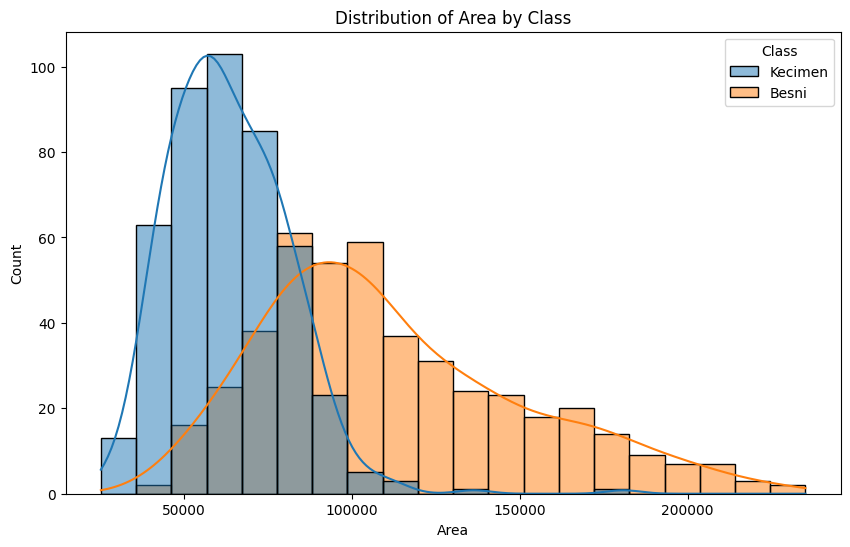

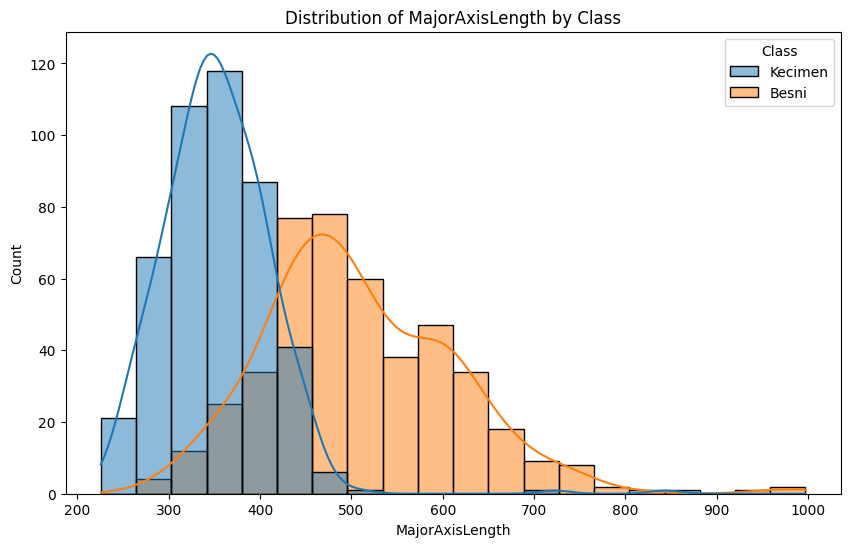

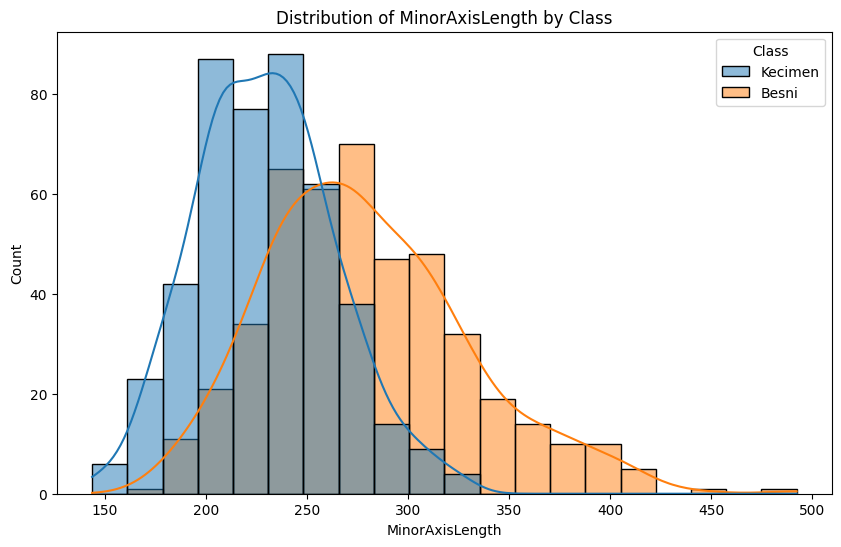

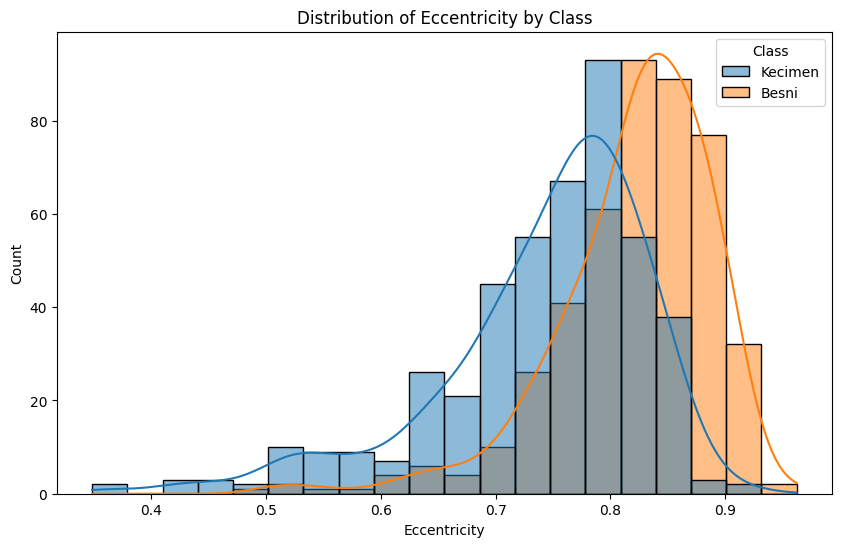

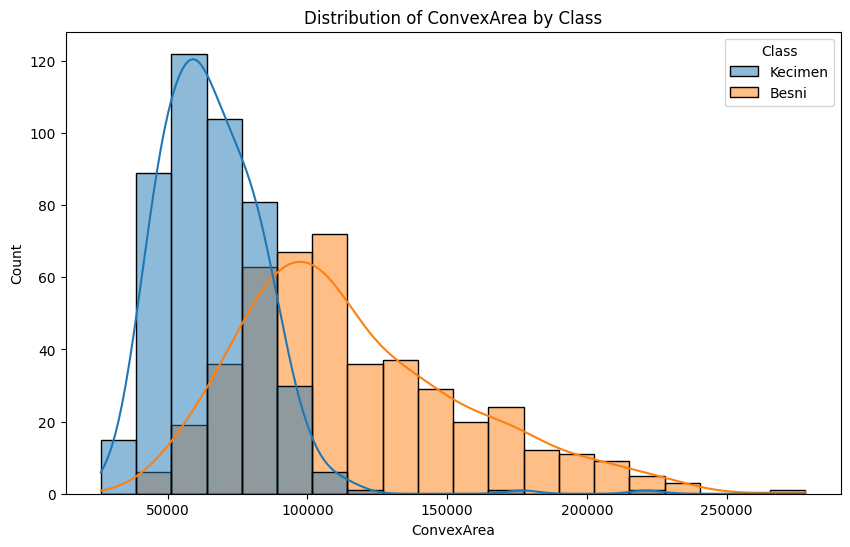

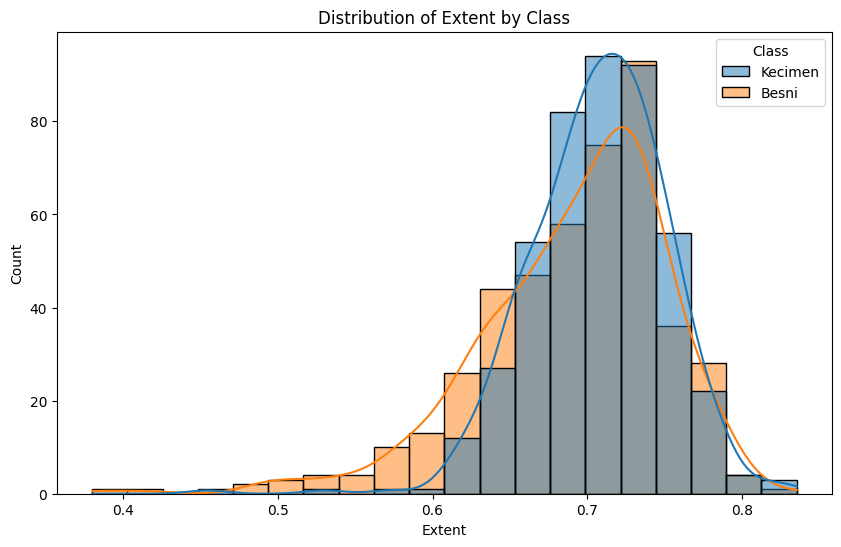

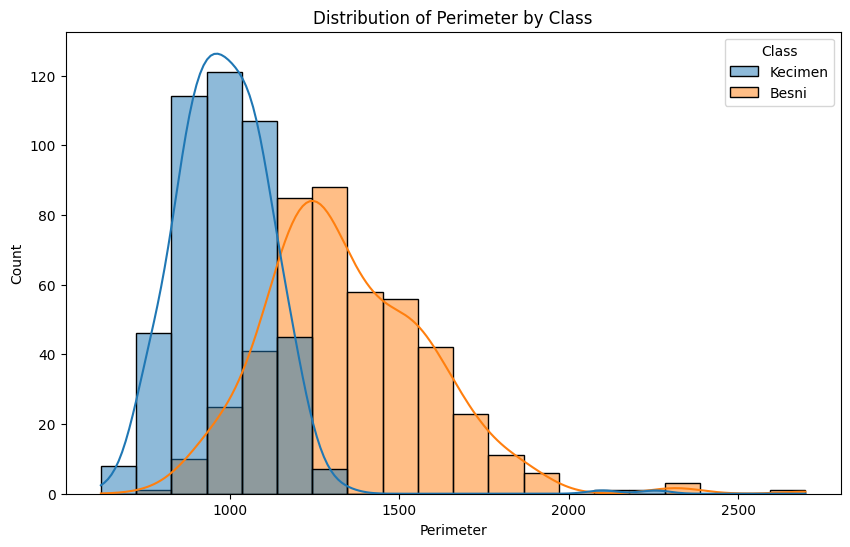

In [21]:
for column in numerical_features:

  plt.figure(figsize=(10, 6))
  sns.histplot(data=df, x=column, hue='Class', kde=True, bins=20)
  plt.title(f'Distribution of {column} by Class')
  plt.show()


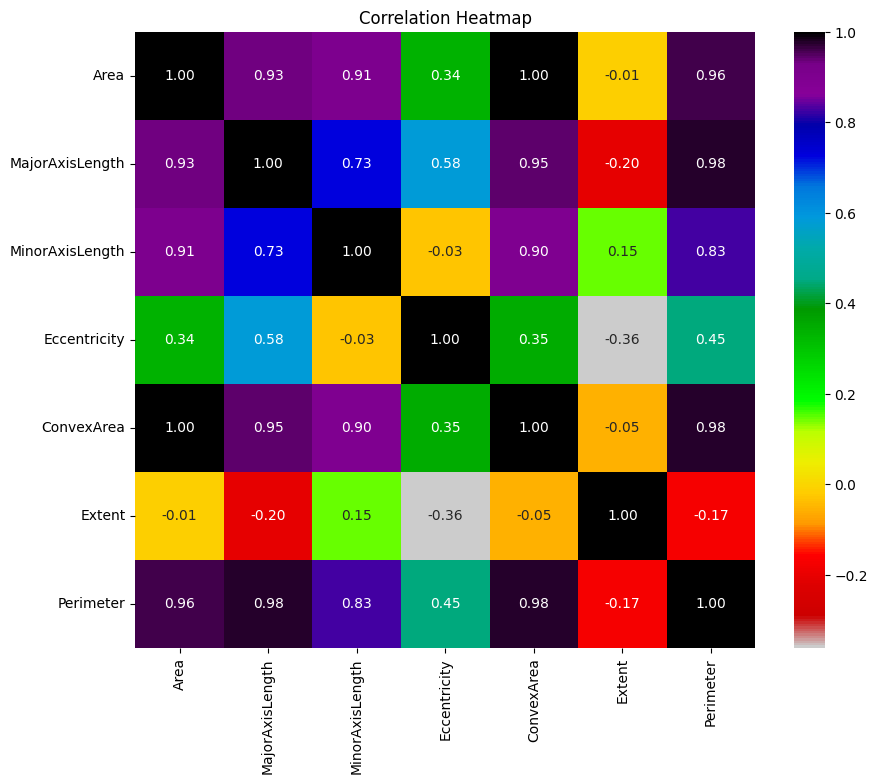

In [22]:
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='nipy_spectral_r', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


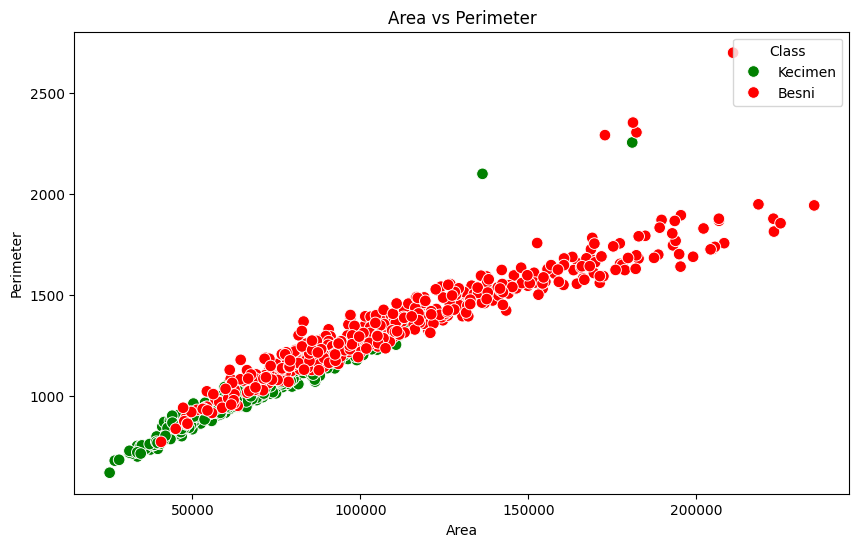

In [23]:
plt.figure(figsize=(10,6))

sns.scatterplot(data=df, x="Area", y="Perimeter", palette={'Kecimen': 'Green', 'Besni': 'Red'}, hue="Class", s=70)

plt.title("Area vs Perimeter")
plt.show()

In [24]:
label_encoder = LabelEncoder()

df["Class_encoded"] = label_encoder.fit_transform(df["Class"])

print(df[["Class", "Class_encoded"]].head(10))

     Class  Class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1
5  Kecimen              1
6  Kecimen              1
7  Kecimen              1
8  Kecimen              1
9  Kecimen              1


In [25]:
X = df[numerical_features]
y = df["Class_encoded"]

print("X Shape: ", X.shape)
print("y shape: ", y.shape)

X Shape:  (900, 7)
y shape:  (900,)


In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

In [27]:
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 720
Testing samples: 180


In [28]:
GaussianNB()

GaussianNB()

In [29]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)


GaussianNB()

In [30]:
y_pred = gnb.predict(X_test)

print("Predicted labels:")
print(y_pred)

Predicted labels:
[1 0 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 1 0 0 1 0 1 1 1 1 0 0 1
 1 1 0 1 0 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 1 0
 1 1 0 1 1 1 0 0 1 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1
 1 1 1 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 1 1 0 1 1 1 0 0 1 0 1]


In [31]:
comparison=pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison.head(20))

     Actual  Predicted
502       0          1
637       0          0
701       0          0
237       1          1
707       0          0
64        1          1
530       0          0
3         1          1
423       1          1
178       1          1
248       1          1
203       1          1
177       1          1
720       0          1
552       0          0
100       1          1
329       1          1
639       0          1
619       0          0
892       0          0


In [32]:
comparison["Actual_Class"] = label_encoder.inverse_transform(comparison["Actual"])

comparison["Predicted_Class"] = label_encoder.inverse_transform(comparison["Predicted"])

print(comparison.head(20))

     Actual  Predicted Actual_Class Predicted_Class
502       0          1        Besni         Kecimen
637       0          0        Besni           Besni
701       0          0        Besni           Besni
237       1          1      Kecimen         Kecimen
707       0          0        Besni           Besni
64        1          1      Kecimen         Kecimen
530       0          0        Besni           Besni
3         1          1      Kecimen         Kecimen
423       1          1      Kecimen         Kecimen
178       1          1      Kecimen         Kecimen
248       1          1      Kecimen         Kecimen
203       1          1      Kecimen         Kecimen
177       1          1      Kecimen         Kecimen
720       0          1        Besni         Kecimen
552       0          0        Besni           Besni
100       1          1      Kecimen         Kecimen
329       1          1      Kecimen         Kecimen
639       0          1        Besni         Kecimen
619       0 

In [33]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy", accuracy)
print("Accuracy (%)", accuracy*100)

Accuracy 0.8166666666666667
Accuracy (%) 81.66666666666667


In [34]:
precision = precision_score(y_test, y_pred)
print("Precision", precision)

Precision 0.7522123893805309


In [35]:
recall = recall_score(y_test, y_pred)
print("Recall", recall)


Recall 0.9444444444444444


In [36]:
f1 = f1_score(y_test, y_pred)
print("F1 Score", f1)


F1 Score 0.8374384236453202


In [37]:
print(f"Model Performance:\nAccuracy: {accuracy:.2f}\nPrecision: {precision:.2f}\nRecall: {recall:.2f}\nF1 Score: {f1:.2f}")

Model Performance:
Accuracy: 0.82
Precision: 0.75
Recall: 0.94
F1 Score: 0.84


Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.69      0.79        90
           1       0.75      0.94      0.84        90

    accuracy                           0.82       180
   macro avg       0.84      0.82      0.81       180
weighted avg       0.84      0.82      0.81       180



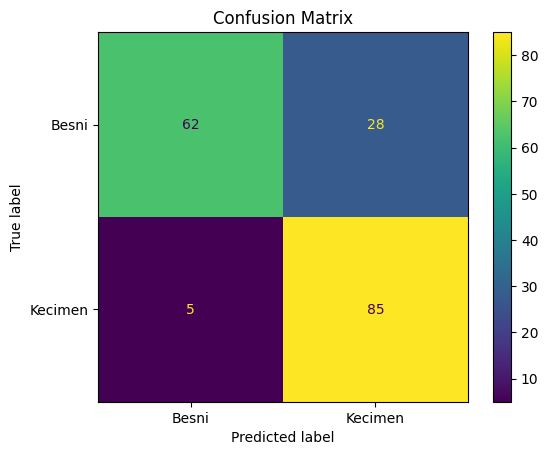

In [38]:
print('Classification Report:\n', classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
display.plot()
plt.title('Confusion Matrix')
plt.show()

In [39]:
from sklearn.metrics import accuracy_score
y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.8263888888888888
Testing Accuracy: 0.8166666666666667


In [40]:
GaussianNB(priors=None)

GaussianNB()